In [6]:
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#Read the csv files

chevalier_path = "../data/nestorowa_singlecell_raw_data_taken_from_bonesis_paper.tsv"
QC_filtered_cells_path = "output/filtered_base.tsv"
qc_metrics_path = "../data/intermediary/cell_QC_metrics.tsv"
conversion_table_path = "output/ensembl_to_symbol.tsv"

chevalier_df = pd.read_csv(chevalier_path, sep="\t", index_col=0)
df_qc_filtered_data = pd.read_csv(QC_filtered_cells_path, sep="\t", index_col=0)
qc_metrics_df = pd.read_csv(qc_metrics_path, sep="\t", index_col=0)
conversion_table_df = pd.read_csv(conversion_table_path, sep="\t", index_col=0)

# Create a dictionary for quick lookup
id_to_symbol = conversion_table_df['symbol'].to_dict()

In [4]:
#Compare the size of the df
print(f"Chevalier df shape: {chevalier_df.shape}")
print(f"Our Qc-filtered data shape: {df_qc_filtered_data.shape}")

Chevalier df shape: (4768, 1656)
Our Qc-filtered data shape: (43152, 1691)


### Normalization of the matrix

The goal of the normalization process i sto compensate for variation due to sampling effects.

Three main methods are mentionned on sc-best-practices.org:
- shifted logarithm
- scran nnormalization
- analytic Pearson's residues approximation.

The article from **Nestorowa et al.** mentions using two processes for normalization:
- resizing the data using a new method described in **Lun et al. (2016)**
- reshaping the data with a log2 transformation.

## 1. Load & transform the data

The use of scanpy requires to put data in AnnData format. We bind the previously QC filtered data with its metrics to be able to plot some visualisations.

In [7]:
#Getting data in anndata format
df_data = df_qc_filtered_data.copy()

#Converting into int
float_cols = df_data.select_dtypes(include=['float', 'float64']).columns
df_data[float_cols] = df_data[float_cols].astype("int64")

# Get cells in lines and genes in columns
df_data = df_data.T

#Filter the qc metrics on the conserved genes
common_cells = df_data.index.intersection(qc_metrics_df.index)
df_metrics_filtered = qc_metrics_df.loc[common_cells]

adata = ad.AnnData(X=df_data.values, obs=df_metrics_filtered)

#Get a copy of the original gene names in the var dataframe
adata.var['gene_names'] = df_data.columns

#Get a copy of the data
adata.layers["counts"] = adata.X.copy()

print(adata)

AnnData object with n_obs × n_vars = 1691 × 43152
    obs: 'cell', 'raw_total_reads', 'mapped_reads', 'assigned_feature_reads', 'nuclear_reads', 'detected_genes', 'mitochondrial_reads', 'ercc_reads', 'mito_pct_mapped', 'ercc_pct_mapped', 'pass_nuclear', 'pass_genes', 'pass_mito', 'pass_ercc', 'pass_all'
    var: 'gene_names'
    layers: None (.X), 'counts'


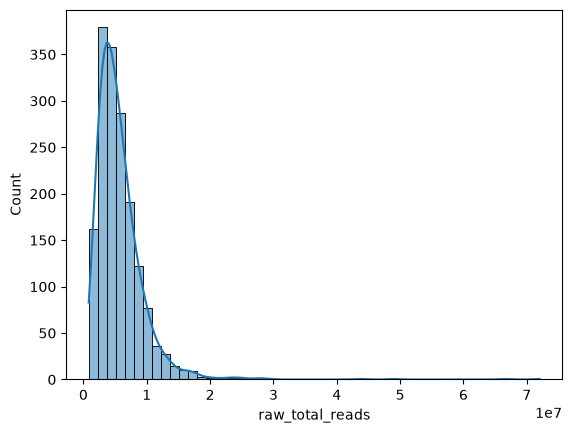

In [8]:
p1= sns.histplot(data=adata.obs, x='raw_total_reads', bins=50, kde=True)

### 2.1 Normalization by logarithmic shift

In [9]:
scales_counts = sc.pp.normalize_total(adata, target_sum=None, inplace=False)
# log1p transform
adata.layers["log1p_norm"] = sc.pp.log1p(scales_counts["X"], copy=True)

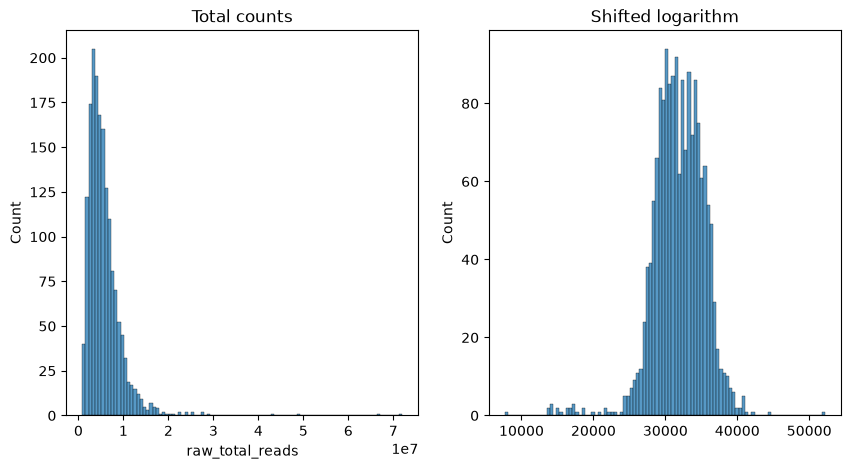

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
p1 = sns.histplot(adata.obs["raw_total_reads"], bins=100, kde=False, ax=axes[0])
axes[0].set_title("Total counts")
p2 = sns.histplot(adata.layers["log1p_norm"].sum(1), bins=100, kde=False, ax=axes[1])
axes[1].set_title("Shifted logarithm")
plt.show()

# blablabal

In [ ]:
# 2. Normalisation par les résidus de Pearson (stabilisation de la variance)
sc.experimental.pp.normalize_pearson_residuals(adata)

# 3. Sélection des gènes hautement variables (HVG)
sc.experimental.pp.highly_variable_genes(
    adata, 
    flavor="pearson_residuals", 
    n_top_genes=5000
)

C:\Users\leave\AppData\Local\Temp\ipykernel_27776\1177979852.py:8: UserWarning: `flavor='pearson_residuals'` expects raw count data, but non-integers were found.
  sc.experimental.pp.highly_variable_genes(


In [ ]:
#Getting the gene list from adata highly variable, where variable is True
hvg_genes = adata.var[adata.var['highly_variable']].index.tolist()

#Convert the list with the ensembl ids to gene symbols using the conversion table
hvg_symbols = [id_to_symbol.get(gene_id, gene_id) for gene_id in hvg_genes]

#Compare the list of hvg_symbols to the list of genes in chevalier_df, and print the number of genes in common
common_genes = set(hvg_symbols) & set(chevalier_df.index)
print(f"Number of common genes: {len(common_genes)}")


Number of common genes: 1240


In [ ]:
#Annotating mitochondrial genes
grcm38_mito_ensembl = [f"ENSMUSG000000{i}" for i in range(64336, 64362)] + \
                      [f"ENSMUSG000000{i}" for i in range(64363, 64373)] + \
                      ["ENSMUSG00000065947"]

assert len(grcm38_mito_ensembl) == 37

### 1. Suppressing genes that have very low expression 

Suppress genes that have null counts in almost all cells.

In [ ]:
df_filtered = df_qc_filtered_data.copy()

Text(0, 0.5, 'Frequency')

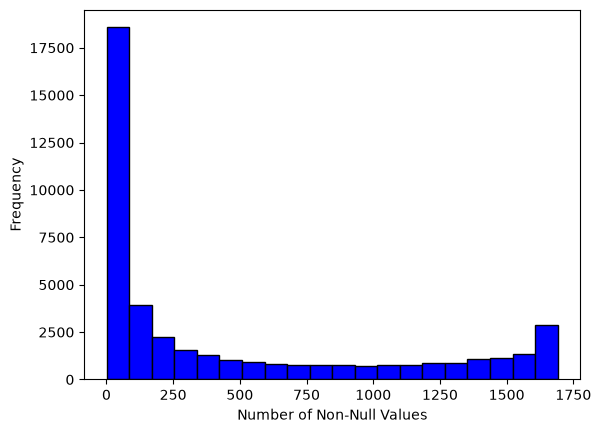

In [ ]:
#Create a df counting the number of non null values for each row (gene) in the filtered df
non_null_counts =  (df_filtered != 0.0).sum(axis=1)


#plot a histogram of the non null counts
import matplotlib.pyplot as plt
non_null_counts.plot(kind="hist", bins=20, edgecolor="black", color="blue")
plt.xlabel("Number of Non-Null Values")
plt.ylabel("Frequency")


In [ ]:
# 2. Extraire et afficher les résultats pour 0, 1, 2 et 3 valeurs non-nulles
for k in [0, 1, 2,10,80,160,250,320,845]:
    subset_index = df_filtered.index[non_null_counts <= k].tolist()
    count = len(subset_index)

    print(f"=== Lignes avec au moins {k} valeurs non-nulles ===")
    print(f"Nombre de personnes/cellules : {count}")
    print(f"Liste des identifiants/index : {subset_index}\n")

In [ ]:
#Add the name column of the genes in second place to the filtered df by using the conversion table ensembl_to_symbol
df_names = conversion_table_df.join(original_filtered_cells_df, how='right')
df_names.index.name = "gene_id"

df_names.head(5)


,symbol,HSPC_025,HSPC_031,HSPC_037,LT-HSC_001,HSPC_001,HSPC_008,HSPC_014,HSPC_020,HSPC_026,...,Prog_851,Prog_809,Prog_816,Prog_822,Prog_828,Prog_834,Prog_840,Prog_846,Prog_852,Prog_810
gene_id,,,,,,,,,,,,,,,,,,,,,
ENSMUSG00000000001,Gnai3,185.0,2.0,2.0,136.0,232.0,354.0,181.0,318.0,4.0,...,43.0,1652.0,182.0,500.0,516.0,137.0,267.0,317.0,85.0,676.0
ENSMUSG00000000003,Pbsn,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ENSMUSG00000000028,Cdc45,4.0,3.0,1.0,1.0,2.0,2.0,0.0,122.0,103.0,...,5.0,4.0,50.0,401.0,293.0,5.0,596.0,649.0,102.0,457.0
ENSMUSG00000000031,H19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ENSMUSG00000000037,Scml2,0.0,0.0,0.0,0.0,0.0,1.0,20.0,0.0,59.0,...,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,134.0
